In [ ]:
!pip install gurobipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.4/14.4 MB 84.0 MB/s eta 0:00:00


In [ ]:
print("Running time 4 seconds")
print("Optimal Value of maximum_minimum_origin 232+320+320+376+348+272+368+368+468+328=3400")
print("Optimal Value of maximum_minimum_p95_p5 336+448+408+448+376+320+400+416+532+352=4036")

Running time 4 seconds
Optimal Value of maximum_minimum_origin 232+320+320+376+348+272+368+368+468+328=3400
Optimal Value of maximum_minimum_p95_p5 336+448+408+448+376+320+400+416+532+352=4036


In [ ]:
import json
import gurobipy as gp
from gurobipy import GRB
import numpy as np
from math import comb, floor

# Load and process the dataset from JSON
with open('10-0.json', 'r') as f:
    data = json.load(f)

# Function to calculate nominal CPU utilization (average) and uncertainty range (max - avg)
def calculate_cpu_intervals(cpu_usage):
    u_c = np.mean(cpu_usage)  # Nominal CPU utilization (average)
    u_r = np.max(cpu_usage) - u_c  # Uncertainty range (max - average)
    return u_c, u_r

# Function to compute B based on N and Gamma
def compute_B(N, Gamma):
    """
    Compute B(N,Gamma) according to Bertsimas and Sim formula
    """
    nu = (Gamma + N) / 2
    mu = nu - floor(nu)
    floor_nu = floor(nu)

    # First term
    first_term = (1 - mu) * comb(N, floor_nu)

    # Summation term
    summation_term = sum(comb(N, l) for l in range(floor_nu + 1, N + 1))

    # Final result
    B_N_Gamma = (1 / (pow(2, N))) * (first_term + summation_term)
    return B_N_Gamma

# Function to compute Gamma based on N and alpha
def compute_Gamma(N, alpha):
    """
    Find minimum Gamma such that B(N,Gamma) <= alpha
    """
    Gamma = 0
    while Gamma <= N:
        B_N_Gamma = compute_B(N, Gamma)
        if B_N_Gamma <= alpha:
            return Gamma
        Gamma += 1
    return N  # Return N if no suitable Gamma is found
optimal_value_list=[]
Min_set_list=[]
Max_set_list=[]
for j in range(101):
  optimal_value=0
  Min_set=0
  Max_set=0
  # Iterate through each PM in the dataset
  for pm in data:
      pm_id = pm["pm_id"]
      total_cpu = pm["total_cpu"]
      total_memory = pm["total_memory"]
      threshold = pm["threshold"] * total_cpu  # Hotspot threshold in terms of CPU

      vms = pm["vms"]
      N = len(vms)  # Number of VMs

      u_c = []
      u_r = []
      memory = []

      # Process each VM
      for vm in vms:
          cpu_usage = vm["cpu_usage"]
          mem = vm["memory"]
          u_c_i, u_r_i = calculate_cpu_intervals(cpu_usage)

          u_c.append(u_c_i)
          u_r.append(u_r_i)
          memory.append(mem)

      alpha = j/100  # Example alpha value; adjust as needed
      Gamma = compute_Gamma(N, alpha)
      print("Gamma: ")
      print(Gamma)
      print("---------------------------------------------------------------------")

      # Initialize Gurobi model
      model = gp.Model(f"PM_{pm_id}_VM_Migration")

      # Variables
      x_vars = model.addVars(N, vtype=GRB.BINARY, name="x")  # x_i = 1 if VM i is in MinSet
      y_vars = model.addVars(N, vtype=GRB.BINARY, name="y")  # y_i = 1 if VM i is in MaxSet
      R_k = model.addVars(range(N + 1), vtype=GRB.BINARY, name="R_k")

      # Objective: Maximize the memory of the VMs retained on the PM
      model.setObjective(gp.quicksum(memory[i] * (x_vars[i] + y_vars[i]) for i in range(N)), GRB.MAXIMIZE)

      # 3b Ensure exactly one R_k is selected
      model.addConstr(gp.quicksum(R_k[k] for k in range(N + 1)) == 1, "unique_k_constraint")

      # 3c Ensure that each VM is either in the MinSet or MaxSet, but not both
      model.addConstrs((x_vars[i] + y_vars[i] <= 1 for i in range(N)), "one_set_constraint")

      # 3d Total number of VMs kept should match the selected k
      model.addConstr(
          gp.quicksum(x_vars[i] + y_vars[i] for i in range(N)) ==
          gp.quicksum(k * R_k[k] for k in range(N + 1)),
          "total_vm_constraint"
      )

      # 3e Number of VMs in MaxSet should match Gamma for the selected k
      model.addConstr(
          gp.quicksum(y_vars[i] for i in range(N)) ==
          gp.quicksum(Gamma * R_k[k] for k in range(N + 1)),
          "maxset_size_constraint"
      )

      #3f
      S = model.addVar(vtype=GRB.CONTINUOUS, name="S")
      model.addConstrs((x_vars[i] * u_r[i] <= S for i in range(N)), "minset_separation")

      #3g
      G = max(u_r)  # Maximum radius among all VMs
      model.addConstrs((G - S >= y_vars[i] * (G - u_r[i]) for i in range(N)), "big_m_constraint")

      # 3h Total CPU capacity constraint (robust constraint)
      model.addConstr(
          gp.quicksum((x_vars[i] + y_vars[i])* u_c[i] for i in range(N)) +
          gp.quicksum(y_vars[i] * u_r[i] for i in range(N)) <= threshold,
          "capacity_constraint"
      )

      #3i
      R_k = model.addVars(range(N + 1), vtype=GRB.BINARY, name="R_k")
      model.addConstr(gp.quicksum(R_k[k] for k in range(N + 1)) == 1, "unique_k_constraint")

      #3L
      model.addConstr(S >= 0, "S_non_negative")

      # Optimize the model
      model.optimize()

      # Print results for this PM
      if model.status == GRB.OPTIMAL:
          optimal_value=optimal_value+model.ObjVal
          print(f"\nOptimal VMs to keep on PM {pm_id}:")

          for i in range(N):
              if x_vars[i].x > 0.5:
                  print(f"VM {vms[i]['vm_id']} is in MinSet (nominal usage): {u_c[i]:.2f}")
                  Min_set=Min_set+1
              elif y_vars[i].x > 0.5:
                  print(f"VM {vms[i]['vm_id']} is in MaxSet (worst-case usage): {u_c[i]:.2f} + {u_r[i]:.2f}")
                  Max_set=Max_set+1
      else:
          print(f"No optimal solution found for PM {pm_id}.")
  optimal_value_list.append(optimal_value)
  Min_set_list.append(Min_set)
  Max_set_list.append(Max_set)

串流輸出內容已截斷至最後 5000 行。
VM 9bb06d3e-164b-4c4d-b9c2-84d931a9cdda is in MinSet (nominal usage): 18.82
VM 62f02c8f-4203-47ff-9be0-b60b0faddac2 is in MinSet (nominal usage): 1.73
VM 3ea97ad4-b193-45d8-9955-8ce188c512dc is in MinSet (nominal usage): 1.34
VM e6312e30-01cb-467c-9935-b64bf9df2d06 is in MinSet (nominal usage): 8.50
VM e87704b1-08cb-40e1-bc3e-29548d7ff793 is in MinSet (nominal usage): 4.34
VM 885ef3de-cd17-441d-a68e-8d0baffca0dc is in MinSet (nominal usage): 1.33
VM e90c72ec-5807-4b8c-9493-bc4544092565 is in MinSet (nominal usage): 3.55
VM 27ed2655-4c72-4d27-a612-cece5b7e3612 is in MinSet (nominal usage): 4.88
VM 205314a9-6885-4e64-9742-9751b71643ce is in MinSet (nominal usage): 0.85
VM c377e991-2261-4ee3-9f1f-d049099f9097 is in MinSet (nominal usage): 6.49
VM a8d31e55-979f-4037-969e-d49228c25e29 is in MinSet (nominal usage): 3.13
VM 648c96c8-d9d3-41c3-a527-b80895d1f92d is in MinSet (nominal usage): 2.94
VM ad1ce6a5-f2a2-46b4-9c4f-f6e166f5bb24 is in MinSet (nominal usage): 6.65
Gam

In [ ]:
optimal_value

4736.0

In [ ]:
len(optimal_value_list)

101

In [ ]:
optimal_value_list[34]

3400.0

In [ ]:
np.linspace(0,100,101)

array([  0.,   1.,   2.,   3.,   4.,   5.,   6.,   7.,   8.,   9.,  10.,
        11.,  12.,  13.,  14.,  15.,  16.,  17.,  18.,  19.,  20.,  21.,
        22.,  23.,  24.,  25.,  26.,  27.,  28.,  29.,  30.,  31.,  32.,
        33.,  34.,  35.,  36.,  37.,  38.,  39.,  40.,  41.,  42.,  43.,
        44.,  45.,  46.,  47.,  48.,  49.,  50.,  51.,  52.,  53.,  54.,
        55.,  56.,  57.,  58.,  59.,  60.,  61.,  62.,  63.,  64.,  65.,
        66.,  67.,  68.,  69.,  70.,  71.,  72.,  73.,  74.,  75.,  76.,
        77.,  78.,  79.,  80.,  81.,  82.,  83.,  84.,  85.,  86.,  87.,
        88.,  89.,  90.,  91.,  92.,  93.,  94.,  95.,  96.,  97.,  98.,
        99., 100.])

Text(0, 0.5, 'Total memory usage of physical machine')

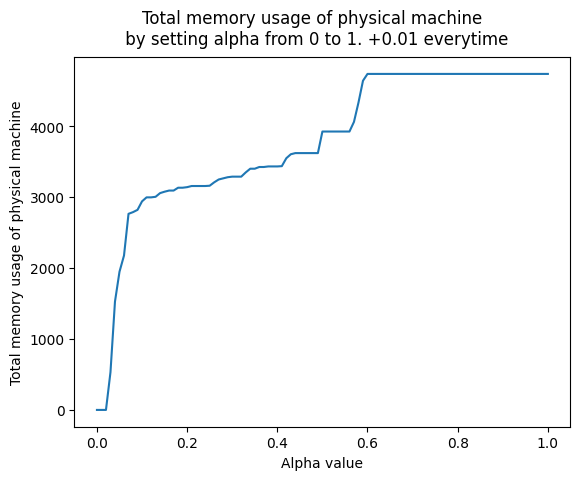

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure()
plt.plot(np.linspace(0,100,101)/100,optimal_value_list)
fig.suptitle('Total memory usage of physical machine \n \
by setting alpha from 0 to 1. +0.01 everytime')
plt.xlabel('Alpha value')
plt.ylabel('Total memory usage of physical machine')

Text(0, 0.5, 'Number of max set and min set')

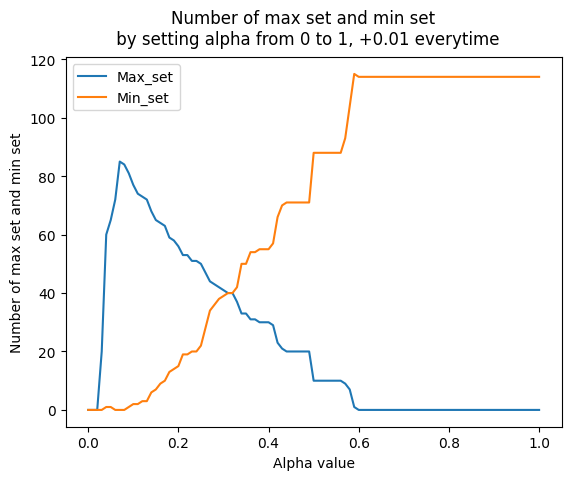

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure()
plt.plot(np.linspace(0,100,101)/100,Max_set_list, label="Max_set")
plt.plot(np.linspace(0,100,101)/100,Min_set_list, label="Min_set")
plt.legend()
fig.suptitle('Number of max set and min set \n \
by setting alpha from 0 to 1, +0.01 everytime')
plt.xlabel('Alpha value')
plt.ylabel('Number of max set and min set')

<ipython-input-48-0065c7298959>:4: RuntimeWarning: invalid value encountered in divide
  plt.plot(np.linspace(0,100,101)/100,np.array(Max_set_list)/(np.array(Max_set_list)+np.array(Min_set_list)), label="Max_set/(Max_set+Min_set)")
<ipython-input-48-0065c7298959>:5: RuntimeWarning: invalid value encountered in divide
  plt.plot(np.linspace(0,100,101)/100,np.array(Min_set_list)/(np.array(Max_set_list)+np.array(Min_set_list)), label="Min_set/(Max_set+Min_set)")


Text(0, 0.5, 'Ratio of max set and min set')

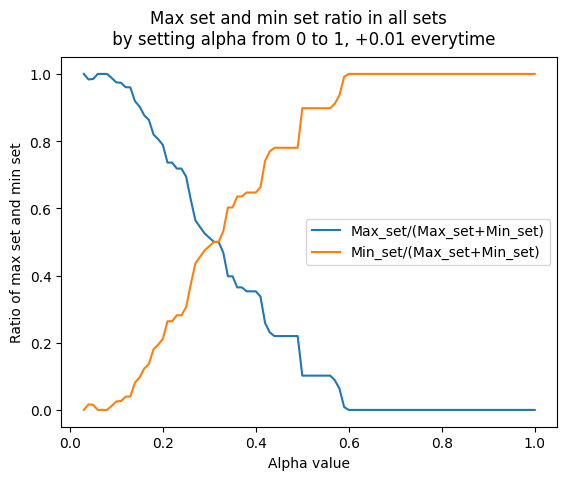

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure()
plt.plot(np.linspace(0,100,101)/100,np.array(Max_set_list)/(np.array(Max_set_list)+np.array(Min_set_list)), label="Max_set/(Max_set+Min_set)")
plt.plot(np.linspace(0,100,101)/100,np.array(Min_set_list)/(np.array(Max_set_list)+np.array(Min_set_list)), label="Min_set/(Max_set+Min_set)")
plt.legend()
fig.suptitle('Max set and min set ratio in all sets \n \
by setting alpha from 0 to 1, +0.01 everytime')
plt.xlabel('Alpha value')
plt.ylabel('Ratio of max set and min set')

Text(0, 0.5, 'Number of virtual machines')

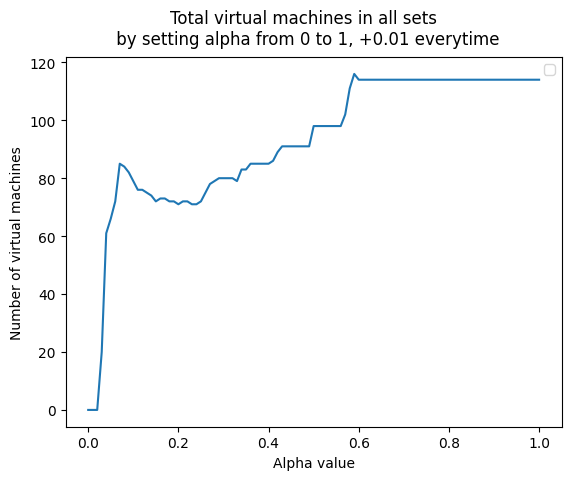

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure()
plt.plot(np.linspace(0,100,101)/100,(np.array(Max_set_list)+np.array(Min_set_list)))
plt.legend()
fig.suptitle('Total virtual machines in all sets \n \
by setting alpha from 0 to 1, +0.01 everytime')
plt.xlabel('Alpha value')
plt.ylabel('Number of virtual machines')

In [ ]:
#max_min_p95_p5
import json
import gurobipy as gp
from gurobipy import GRB
import numpy as np
from math import comb, floor

# Load and process the dataset from JSON
with open('10-0.json', 'r') as f:
    data = json.load(f)

# Function to calculate nominal CPU utilization (average) and uncertainty range (max - avg)
def calculate_cpu_intervals(cpu_usage):
    u_c = np.mean(cpu_usage)  # Nominal CPU utilization (average)
    u_r = (np.max(cpu_usage) - u_c)*0.45  # Uncertainty range (max - average), 0.45 for max_min_p95_5
    return u_c, u_r

# Function to compute B based on N and Gamma
def compute_B(N, Gamma):
    """
    Compute B(N,Gamma) according to Bertsimas and Sim formula
    """
    nu = (Gamma + N) / 2
    mu = nu - floor(nu)
    floor_nu = floor(nu)

    # First term
    first_term = (1 - mu) * comb(N, floor_nu)

    # Summation term
    summation_term = sum(comb(N, l) for l in range(floor_nu + 1, N + 1))

    # Final result
    B_N_Gamma = (1 / (pow(2, N))) * (first_term + summation_term)
    return B_N_Gamma

# Function to compute Gamma based on N and alpha
def compute_Gamma(N, alpha):
    """
    Find minimum Gamma such that B(N,Gamma) <= alpha
    """
    Gamma = 0
    while Gamma <= N:
        B_N_Gamma = compute_B(N, Gamma)
        if B_N_Gamma <= alpha:
            return Gamma
        Gamma += 1
    return N  # Return N if no suitable Gamma is found
optimal_value_list_1=[]
Min_set_list_1=[]
Max_set_list_1=[]
for j in range(101):
  optimal_value=0
  Min_set=0
  Max_set=0
  # Iterate through each PM in the dataset
  for pm in data:
      pm_id = pm["pm_id"]
      total_cpu = pm["total_cpu"]
      total_memory = pm["total_memory"]
      threshold = pm["threshold"] * total_cpu  # Hotspot threshold in terms of CPU

      vms = pm["vms"]
      N = len(vms)  # Number of VMs

      u_c = []
      u_r = []
      memory = []

      # Process each VM
      for vm in vms:
          cpu_usage = vm["cpu_usage"]
          mem = vm["memory"]
          u_c_i, u_r_i = calculate_cpu_intervals(cpu_usage)

          u_c.append(u_c_i)
          u_r.append(u_r_i)
          memory.append(mem)

      alpha = j/100  # Example alpha value; adjust as needed
      Gamma = compute_Gamma(N, alpha)
      print("Gamma: ")
      print(Gamma)
      print("---------------------------------------------------------------------")

      # Initialize Gurobi model
      model = gp.Model(f"PM_{pm_id}_VM_Migration")

      # Variables
      x_vars = model.addVars(N, vtype=GRB.BINARY, name="x")  # x_i = 1 if VM i is in MinSet
      y_vars = model.addVars(N, vtype=GRB.BINARY, name="y")  # y_i = 1 if VM i is in MaxSet
      R_k = model.addVars(range(N + 1), vtype=GRB.BINARY, name="R_k")

      # Objective: Maximize the memory of the VMs retained on the PM
      model.setObjective(gp.quicksum(memory[i] * (x_vars[i] + y_vars[i]) for i in range(N)), GRB.MAXIMIZE)

      # 3b Ensure exactly one R_k is selected
      model.addConstr(gp.quicksum(R_k[k] for k in range(N + 1)) == 1, "unique_k_constraint")

      # 3c Ensure that each VM is either in the MinSet or MaxSet, but not both
      model.addConstrs((x_vars[i] + y_vars[i] <= 1 for i in range(N)), "one_set_constraint")

      # 3d Total number of VMs kept should match the selected k
      model.addConstr(
          gp.quicksum(x_vars[i] + y_vars[i] for i in range(N)) ==
          gp.quicksum(k * R_k[k] for k in range(N + 1)),
          "total_vm_constraint"
      )

      # 3e Number of VMs in MaxSet should match Gamma for the selected k
      model.addConstr(
          gp.quicksum(y_vars[i] for i in range(N)) ==
          gp.quicksum(Gamma * R_k[k] for k in range(N + 1)),
          "maxset_size_constraint"
      )

      #3f
      S = model.addVar(vtype=GRB.CONTINUOUS, name="S")
      model.addConstrs((x_vars[i] * u_r[i] <= S for i in range(N)), "minset_separation")

      #3g
      G = max(u_r)  # Maximum radius among all VMs
      model.addConstrs((G - S >= y_vars[i] * (G - u_r[i]) for i in range(N)), "big_m_constraint")

      # 3h Total CPU capacity constraint (robust constraint)
      model.addConstr(
          gp.quicksum((x_vars[i] + y_vars[i])* u_c[i] for i in range(N)) +
          gp.quicksum(y_vars[i] * u_r[i] for i in range(N)) <= threshold,
          "capacity_constraint"
      )

      #3i
      R_k = model.addVars(range(N + 1), vtype=GRB.BINARY, name="R_k")
      model.addConstr(gp.quicksum(R_k[k] for k in range(N + 1)) == 1, "unique_k_constraint")

      #3L
      model.addConstr(S >= 0, "S_non_negative")

      # Optimize the model
      model.optimize()

      # Print results for this PM
      if model.status == GRB.OPTIMAL:
          optimal_value=optimal_value+model.ObjVal
          print(f"\nOptimal VMs to keep on PM {pm_id}:")

          for i in range(N):
              if x_vars[i].x > 0.5:
                  print(f"VM {vms[i]['vm_id']} is in MinSet (nominal usage): {u_c[i]:.2f}")
                  Min_set=Min_set+1
              elif y_vars[i].x > 0.5:
                  print(f"VM {vms[i]['vm_id']} is in MaxSet (worst-case usage): {u_c[i]:.2f} + {u_r[i]:.2f}")
                  Max_set=Max_set+1
      else:
          print(f"No optimal solution found for PM {pm_id}.")
  optimal_value_list_1.append(optimal_value)
  Min_set_list_1.append(Min_set)
  Max_set_list_1.append(Max_set)

串流輸出內容已截斷至最後 5000 行。
Optimal solution found (tolerance 1.00e-04)
Best objective 4.560000000000e+02, best bound 4.560000000000e+02, gap 0.0000%

Optimal VMs to keep on PM 6:
VM 973886a1-43ad-488b-ae55-97e100d957bb is in MinSet (nominal usage): 25.03
VM 9bb06d3e-164b-4c4d-b9c2-84d931a9cdda is in MinSet (nominal usage): 18.82
VM 62f02c8f-4203-47ff-9be0-b60b0faddac2 is in MinSet (nominal usage): 1.73
VM 3ea97ad4-b193-45d8-9955-8ce188c512dc is in MinSet (nominal usage): 1.34
VM e6312e30-01cb-467c-9935-b64bf9df2d06 is in MinSet (nominal usage): 8.50
VM e87704b1-08cb-40e1-bc3e-29548d7ff793 is in MinSet (nominal usage): 4.34
VM 885ef3de-cd17-441d-a68e-8d0baffca0dc is in MinSet (nominal usage): 1.33
VM e90c72ec-5807-4b8c-9493-bc4544092565 is in MinSet (nominal usage): 3.55
VM 27ed2655-4c72-4d27-a612-cece5b7e3612 is in MinSet (nominal usage): 4.88
VM 205314a9-6885-4e64-9742-9751b71643ce is in MinSet (nominal usage): 0.85
VM c377e991-2261-4ee3-9f1f-d049099f9097 is in MinSet (nominal usage): 6.49


Text(0, 0.5, 'Total memory usage of physical machine')

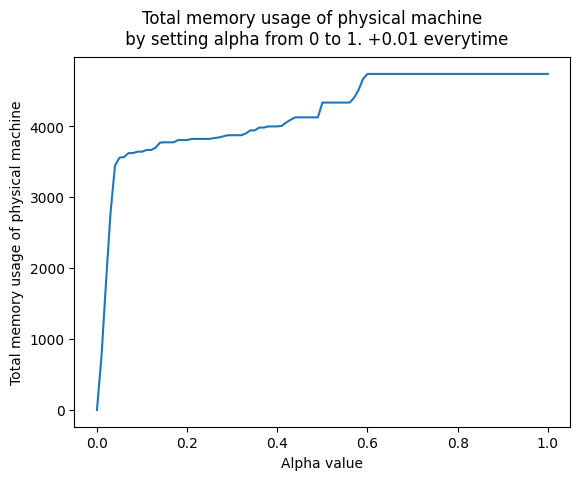

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure()
plt.plot(np.linspace(0,100,101)/100,optimal_value_list_1)
fig.suptitle('Total memory usage of physical machine \n \
by setting alpha from 0 to 1. +0.01 everytime')
plt.xlabel('Alpha value')
plt.ylabel('Total memory usage of physical machine')

Text(0, 0.5, 'Number of max set and min set')

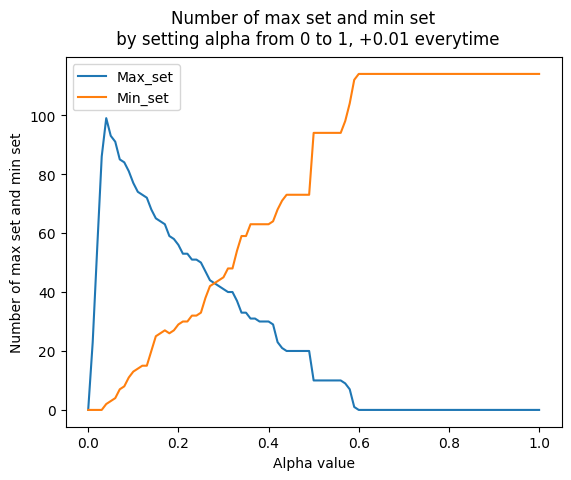

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure()
plt.plot(np.linspace(0,100,101)/100,Max_set_list_1, label="Max_set")
plt.plot(np.linspace(0,100,101)/100,Min_set_list_1, label="Min_set")
plt.legend()
fig.suptitle('Number of max set and min set \n \
by setting alpha from 0 to 1, +0.01 everytime')
plt.xlabel('Alpha value')
plt.ylabel('Number of max set and min set')

<ipython-input-53-4ddb640c9eea>:4: RuntimeWarning: invalid value encountered in divide
  plt.plot(np.linspace(0,100,101)/100,np.array(Max_set_list_1)/(np.array(Max_set_list_1)+np.array(Min_set_list_1)), label="Max_set/(Max_set+Min_set)")
<ipython-input-53-4ddb640c9eea>:5: RuntimeWarning: invalid value encountered in divide
  plt.plot(np.linspace(0,100,101)/100,np.array(Min_set_list_1)/(np.array(Max_set_list_1)+np.array(Min_set_list_1)), label="Min_set/(Max_set+Min_set)")


Text(0, 0.5, 'Ratio of max set and min set')

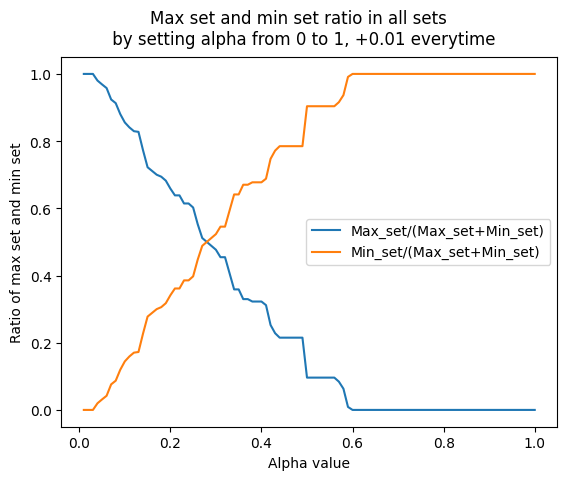

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure()
plt.plot(np.linspace(0,100,101)/100,np.array(Max_set_list_1)/(np.array(Max_set_list_1)+np.array(Min_set_list_1)), label="Max_set/(Max_set+Min_set)")
plt.plot(np.linspace(0,100,101)/100,np.array(Min_set_list_1)/(np.array(Max_set_list_1)+np.array(Min_set_list_1)), label="Min_set/(Max_set+Min_set)")
plt.legend()
fig.suptitle('Max set and min set ratio in all sets \n \
by setting alpha from 0 to 1, +0.01 everytime')
plt.xlabel('Alpha value')
plt.ylabel('Ratio of max set and min set')

Text(0, 0.5, 'Number of virtual machines')

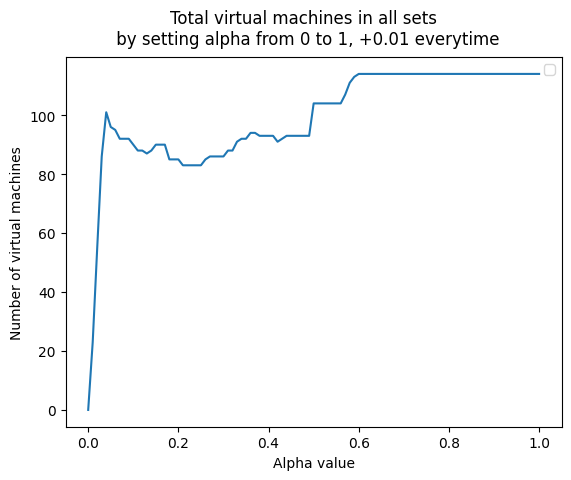

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure()
plt.plot(np.linspace(0,100,101)/100,(np.array(Max_set_list_1)+np.array(Min_set_list_1)))
plt.legend()
fig.suptitle('Total virtual machines in all sets \n \
by setting alpha from 0 to 1, +0.01 everytime')
plt.xlabel('Alpha value')
plt.ylabel('Number of virtual machines')

Text(0, 0.5, 'Total memory usage of physical machine')

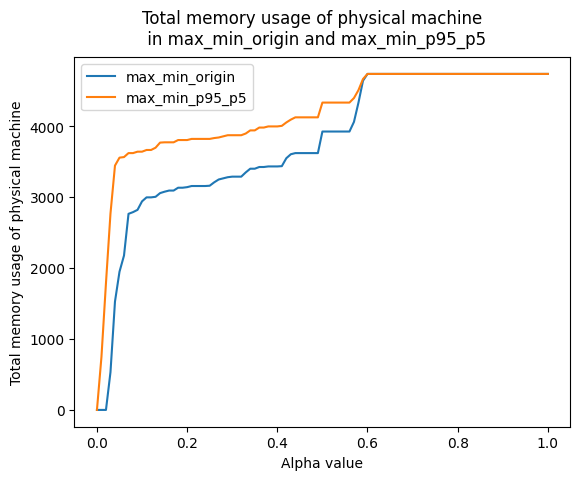

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure()
plt.plot(np.linspace(0,100,101)/100,optimal_value_list, label="max_min_origin")
plt.plot(np.linspace(0,100,101)/100,optimal_value_list_1, label="max_min_p95_p5")
plt.legend()
fig.suptitle("Total memory usage of physical machine \n \
in max_min_origin and max_min_p95_p5")
plt.xlabel('Alpha value')
plt.ylabel('Total memory usage of physical machine')

Text(0, 0.5, 'Number of virtual machines')

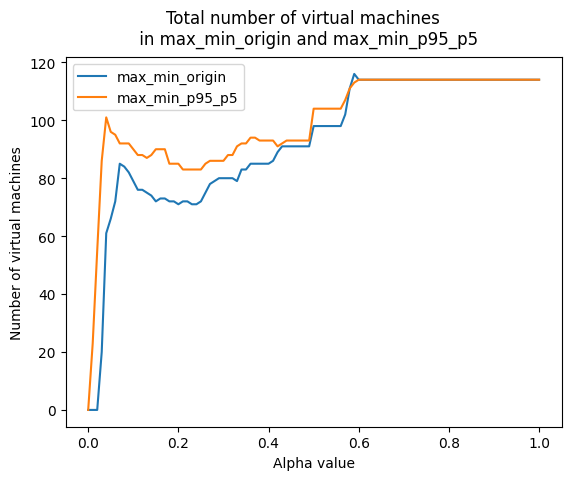

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure()
plt.plot(np.linspace(0,100,101)/100,(np.array(Max_set_list)+np.array(Min_set_list)), label="max_min_origin")
plt.plot(np.linspace(0,100,101)/100,(np.array(Max_set_list_1)+np.array(Min_set_list_1)), label="max_min_p95_p5")
plt.legend()
fig.suptitle("Total number of virtual machines \n \
in max_min_origin and max_min_p95_p5")
plt.xlabel('Alpha value')
plt.ylabel('Number of virtual machines')

In [ ]:
np.argmax(Max_set_list+Min_set_list)

160

In [ ]:
np.argmax(np.array(Max_set_list_1[0:20])+np.array(Min_set_list_1[0:20]))

4

In [ ]:
import json
import gurobipy as gp
from gurobipy import GRB
import numpy as np
from math import comb, floor

# Load and process the dataset from JSON
with open('10-0.json', 'r') as f:
    data = json.load(f)

# Function to calculate nominal CPU utilization (average) and uncertainty range (max - avg)
def calculate_cpu_intervals(cpu_usage):
    u_c = np.mean(cpu_usage)  # Nominal CPU utilization (average)
    u_r = np.max(cpu_usage) - u_c  # Uncertainty range (max - average)
    return u_c, u_r

# Function to compute B based on N and Gamma
def compute_B(N, Gamma):
    """
    Compute B(N,Gamma) according to Bertsimas and Sim formula
    """
    nu = (Gamma + N) / 2
    mu = nu - floor(nu)
    floor_nu = floor(nu)

    # First term
    first_term = (1 - mu) * comb(N, floor_nu)

    # Summation term
    summation_term = sum(comb(N, l) for l in range(floor_nu + 1, N + 1))

    # Final result
    B_N_Gamma = (1 / (pow(2, N))) * (first_term + summation_term)
    return B_N_Gamma

# Function to compute Gamma based on N and alpha
def compute_Gamma(N, alpha):
    """
    Find minimum Gamma such that B(N,Gamma) <= alpha
    """
    Gamma = 0
    while Gamma <= N:
        B_N_Gamma = compute_B(N, Gamma)
        if B_N_Gamma <= alpha:
            return Gamma
        Gamma += 1
    return N  # Return N if no suitable Gamma is found
for j in range(1):
  optimal_value=0
  Min_set=0
  Max_set=0
  # Iterate through each PM in the dataset
  for pm in data:
      pm_id = pm["pm_id"]
      total_cpu = pm["total_cpu"]
      total_memory = pm["total_memory"]
      threshold = pm["threshold"] * total_cpu  # Hotspot threshold in terms of CPU

      vms = pm["vms"]
      N = len(vms)  # Number of VMs

      u_c = []
      u_r = []
      memory = []

      # Process each VM
      for vm in vms:
          cpu_usage = vm["cpu_usage"]
          mem = vm["memory"]
          u_c_i, u_r_i = calculate_cpu_intervals(cpu_usage)

          u_c.append(u_c_i)
          u_r.append(u_r_i)
          memory.append(mem)

      alpha = 6/100  # Example alpha value; adjust as needed
      Gamma = compute_Gamma(N, alpha)
      print("Gamma: ")
      print(Gamma)
      print("---------------------------------------------------------------------")

      # Initialize Gurobi model
      model = gp.Model(f"PM_{pm_id}_VM_Migration")

      # Variables
      x_vars = model.addVars(N, vtype=GRB.BINARY, name="x")  # x_i = 1 if VM i is in MinSet
      y_vars = model.addVars(N, vtype=GRB.BINARY, name="y")  # y_i = 1 if VM i is in MaxSet
      R_k = model.addVars(range(N + 1), vtype=GRB.BINARY, name="R_k")

      # Objective: Maximize the memory of the VMs retained on the PM
      model.setObjective(gp.quicksum(memory[i] * (x_vars[i] + y_vars[i]) for i in range(N)), GRB.MAXIMIZE)

      # 3b Ensure exactly one R_k is selected
      model.addConstr(gp.quicksum(R_k[k] for k in range(N + 1)) == 1, "unique_k_constraint")

      # 3c Ensure that each VM is either in the MinSet or MaxSet, but not both
      model.addConstrs((x_vars[i] + y_vars[i] <= 1 for i in range(N)), "one_set_constraint")

      # 3d Total number of VMs kept should match the selected k
      model.addConstr(
          gp.quicksum(x_vars[i] + y_vars[i] for i in range(N)) ==
          gp.quicksum(k * R_k[k] for k in range(N + 1)),
          "total_vm_constraint"
      )

      # 3e Number of VMs in MaxSet should match Gamma for the selected k
      model.addConstr(
          gp.quicksum(y_vars[i] for i in range(N)) ==
          gp.quicksum(Gamma * R_k[k] for k in range(N + 1)),
          "maxset_size_constraint"
      )

      #3f
      S = model.addVar(vtype=GRB.CONTINUOUS, name="S")
      model.addConstrs((x_vars[i] * u_r[i] <= S for i in range(N)), "minset_separation")

      #3g
      G = max(u_r)  # Maximum radius among all VMs
      model.addConstrs((G - S >= y_vars[i] * (G - u_r[i]) for i in range(N)), "big_m_constraint")

      # 3h Total CPU capacity constraint (robust constraint)
      model.addConstr(
          gp.quicksum((x_vars[i] + y_vars[i])* u_c[i] for i in range(N)) +
          gp.quicksum(y_vars[i] * u_r[i] for i in range(N)) <= threshold,
          "capacity_constraint"
      )

      #3i
      R_k = model.addVars(range(N + 1), vtype=GRB.BINARY, name="R_k")
      model.addConstr(gp.quicksum(R_k[k] for k in range(N + 1)) == 1, "unique_k_constraint")

      #3L
      model.addConstr(S >= 0, "S_non_negative")

      # Optimize the model
      model.optimize()

      # Print results for this PM
      if model.status == GRB.OPTIMAL:
          optimal_value=optimal_value+model.ObjVal
          print(f"\nOptimal VMs to keep on PM {pm_id}:")

          for i in range(N):
              if x_vars[i].x > 0.5:
                  print(f"VM {vms[i]['vm_id']} is in MinSet (nominal usage): {u_c[i]:.2f}")
                  Min_set=Min_set+1
              elif y_vars[i].x > 0.5:
                  print(f"VM {vms[i]['vm_id']} is in MaxSet (worst-case usage): {u_c[i]:.2f} + {u_r[i]:.2f}")
                  Max_set=Max_set+1
      else:
          print(f"No optimal solution found for PM {pm_id}.")


Gamma: 
11
---------------------------------------------------------------------
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (linux64 - "Ubuntu 22.04.3 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 114 rows, 147 columns and 543 nonzeros
Model fingerprint: 0x939a3e77
Variable types: 1 continuous, 146 integer (146 binary)
Coefficient statistics:
  Matrix range     [1e-01, 6e+01]
  Objective range  [4e+00, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 9e+01]
Presolve removed 79 rows and 109 columns
Presolve time: 0.01s
Presolved: 35 rows, 38 columns, 135 nonzeros
Variable types: 1 continuous, 37 integer (37 binary)
Found heuristic solution: objective 168.0000000

Root relaxation: objective 2.026968e+02, 16 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Un

In [ ]:
optimal_value

2176.0

In [ ]:
Max_set

72

In [ ]:
#max_min_p95_95
import json
import gurobipy as gp
from gurobipy import GRB
import numpy as np
from math import comb, floor

# Load and process the dataset from JSON
with open('10-0.json', 'r') as f:
    data = json.load(f)

# Function to calculate nominal CPU utilization (average) and uncertainty range (max - avg)
def calculate_cpu_intervals(cpu_usage):
    u_c = np.mean(cpu_usage)  # Nominal CPU utilization (average)
    u_r = (np.max(cpu_usage) - u_c)*0.45  # Uncertainty range (max - average)
    return u_c, u_r

# Function to compute B based on N and Gamma
def compute_B(N, Gamma):
    """
    Compute B(N,Gamma) according to Bertsimas and Sim formula
    """
    nu = (Gamma + N) / 2
    mu = nu - floor(nu)
    floor_nu = floor(nu)

    # First term
    first_term = (1 - mu) * comb(N, floor_nu)

    # Summation term
    summation_term = sum(comb(N, l) for l in range(floor_nu + 1, N + 1))

    # Final result
    B_N_Gamma = (1 / (pow(2, N))) * (first_term + summation_term)
    return B_N_Gamma

# Function to compute Gamma based on N and alpha
def compute_Gamma(N, alpha):
    """
    Find minimum Gamma such that B(N,Gamma) <= alpha
    """
    Gamma = 0
    while Gamma <= N:
        B_N_Gamma = compute_B(N, Gamma)
        if B_N_Gamma <= alpha:
            return Gamma
        Gamma += 1
    return N  # Return N if no suitable Gamma is found
for j in range(1):
  optimal_value=0
  Min_set=0
  Max_set=0
  # Iterate through each PM in the dataset
  for pm in data:
      pm_id = pm["pm_id"]
      total_cpu = pm["total_cpu"]
      total_memory = pm["total_memory"]
      threshold = pm["threshold"] * total_cpu  # Hotspot threshold in terms of CPU

      vms = pm["vms"]
      N = len(vms)  # Number of VMs

      u_c = []
      u_r = []
      memory = []

      # Process each VM
      for vm in vms:
          cpu_usage = vm["cpu_usage"]
          mem = vm["memory"]
          u_c_i, u_r_i = calculate_cpu_intervals(cpu_usage)

          u_c.append(u_c_i)
          u_r.append(u_r_i)
          memory.append(mem)

      alpha = 6/100  # Example alpha value; adjust as needed
      Gamma = compute_Gamma(N, alpha)
      print("Gamma: ")
      print(Gamma)
      print("---------------------------------------------------------------------")

      # Initialize Gurobi model
      model = gp.Model(f"PM_{pm_id}_VM_Migration")

      # Variables
      x_vars = model.addVars(N, vtype=GRB.BINARY, name="x")  # x_i = 1 if VM i is in MinSet
      y_vars = model.addVars(N, vtype=GRB.BINARY, name="y")  # y_i = 1 if VM i is in MaxSet
      R_k = model.addVars(range(N + 1), vtype=GRB.BINARY, name="R_k")

      # Objective: Maximize the memory of the VMs retained on the PM
      model.setObjective(gp.quicksum(memory[i] * (x_vars[i] + y_vars[i]) for i in range(N)), GRB.MAXIMIZE)

      # 3b Ensure exactly one R_k is selected
      model.addConstr(gp.quicksum(R_k[k] for k in range(N + 1)) == 1, "unique_k_constraint")

      # 3c Ensure that each VM is either in the MinSet or MaxSet, but not both
      model.addConstrs((x_vars[i] + y_vars[i] <= 1 for i in range(N)), "one_set_constraint")

      # 3d Total number of VMs kept should match the selected k
      model.addConstr(
          gp.quicksum(x_vars[i] + y_vars[i] for i in range(N)) ==
          gp.quicksum(k * R_k[k] for k in range(N + 1)),
          "total_vm_constraint"
      )

      # 3e Number of VMs in MaxSet should match Gamma for the selected k
      model.addConstr(
          gp.quicksum(y_vars[i] for i in range(N)) ==
          gp.quicksum(Gamma * R_k[k] for k in range(N + 1)),
          "maxset_size_constraint"
      )

      #3f
      S = model.addVar(vtype=GRB.CONTINUOUS, name="S")
      model.addConstrs((x_vars[i] * u_r[i] <= S for i in range(N)), "minset_separation")

      #3g
      G = max(u_r)  # Maximum radius among all VMs
      model.addConstrs((G - S >= y_vars[i] * (G - u_r[i]) for i in range(N)), "big_m_constraint")

      # 3h Total CPU capacity constraint (robust constraint)
      model.addConstr(
          gp.quicksum((x_vars[i] + y_vars[i])* u_c[i] for i in range(N)) +
          gp.quicksum(y_vars[i] * u_r[i] for i in range(N)) <= threshold,
          "capacity_constraint"
      )

      #3i
      R_k = model.addVars(range(N + 1), vtype=GRB.BINARY, name="R_k")
      model.addConstr(gp.quicksum(R_k[k] for k in range(N + 1)) == 1, "unique_k_constraint")

      #3L
      model.addConstr(S >= 0, "S_non_negative")

      # Optimize the model
      model.optimize()

      # Print results for this PM
      if model.status == GRB.OPTIMAL:
          optimal_value=optimal_value+model.ObjVal
          print(f"\nOptimal VMs to keep on PM {pm_id}:")

          for i in range(N):
              if x_vars[i].x > 0.5:
                  print(f"VM {vms[i]['vm_id']} is in MinSet (nominal usage): {u_c[i]:.2f}")
                  Min_set=Min_set+1
              elif y_vars[i].x > 0.5:
                  print(f"VM {vms[i]['vm_id']} is in MaxSet (worst-case usage): {u_c[i]:.2f} + {u_r[i]:.2f}")
                  Max_set=Max_set+1
      else:
          print(f"No optimal solution found for PM {pm_id}.")

Gamma: 
11
---------------------------------------------------------------------
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (linux64 - "Ubuntu 22.04.3 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 114 rows, 147 columns and 543 nonzeros
Model fingerprint: 0xf2439c44
Variable types: 1 continuous, 146 integer (146 binary)
Coefficient statistics:
  Matrix range     [5e-02, 4e+01]
  Objective range  [4e+00, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 9e+01]
Presolve removed 40 rows and 79 columns
Presolve time: 0.00s
Presolved: 74 rows, 68 columns, 273 nonzeros
Variable types: 1 continuous, 67 integer (67 binary)
Found heuristic solution: objective 168.0000000

Root relaxation: objective 2.737223e+02, 29 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Une

In [ ]:
optimal_value

3564.0

In [ ]:
np.argmax(np.array(Max_set_list[0:20])+np.array(Min_set_list[0:20]))

7

In [ ]:
np.array(Max_set_list[1:101])-np.array(Max_set_list[0:100])

array([  0,   0,  20,  40,   5,   7,  13,  -1,  -3,  -4,  -3,  -1,  -1,
        -4,  -3,  -1,  -1,  -4,  -1,  -2,  -3,   0,  -2,   0,  -1,  -3,
        -3,  -1,  -1,  -1,  -1,   0,  -3,  -4,   0,  -2,   0,  -1,   0,
         0,  -1,  -6,  -2,  -1,   0,   0,   0,   0,   0, -10,   0,   0,
         0,   0,   0,   0,  -1,  -2,  -6,  -1,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0])

Text(0, 0.5, 'Number of virtual machines')

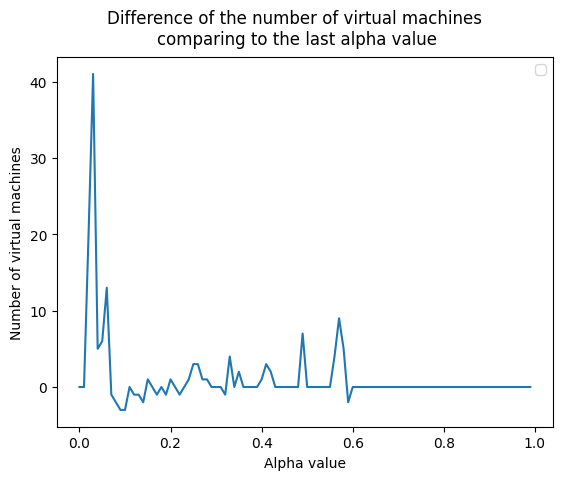

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure()
plt.plot(np.linspace(0,100,101)[0:100]/100,(np.array(Max_set_list)[1:101]+np.array(Min_set_list)[1:101]-np.array(Max_set_list)[0:100]-np.array(Min_set_list)[0:100]))
plt.legend()
fig.suptitle('Difference of the number of virtual machines \n\
comparing to the last alpha value')
plt.xlabel('Alpha value')
plt.ylabel('Number of virtual machines')

Text(0, 0.5, 'Memory Usage')

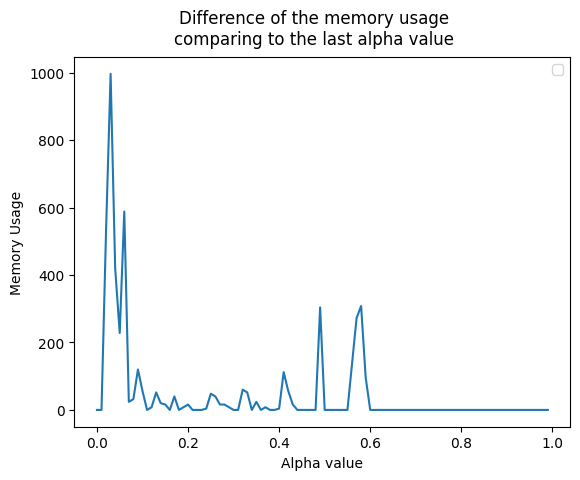

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure()
plt.plot(np.linspace(0,100,101)[0:100]/100,(np.array(optimal_value_list)[1:101]-np.array(optimal_value_list)[0:100]))
plt.legend()
fig.suptitle('Difference of the memory usage\n\
comparing to the last alpha value')
plt.xlabel('Alpha value')
plt.ylabel('Memory Usage')

In [ ]:
np.array(Max_set_list)[1:101]+np.array(Min_set_list)[1:101]-np.array(Max_set_list)[0:100]-np.array(Min_set_list)[0:100]

array([ 0,  0, 20, 41,  5,  6, 13, -1, -2, -3, -3,  0, -1, -1, -2,  1,  0,
       -1,  0, -1,  1,  0, -1,  0,  1,  3,  3,  1,  1,  0,  0,  0, -1,  4,
        0,  2,  0,  0,  0,  0,  1,  3,  2,  0,  0,  0,  0,  0,  0,  7,  0,
        0,  0,  0,  0,  0,  4,  9,  5, -2,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0])

In [ ]:
np.array(optimal_value_list)[1:101]-np.array(optimal_value_list)[0:100]

array([  0.,   0., 532., 996., 420., 228., 588.,  24.,  32., 120.,  56.,
         0.,   8.,  52.,  20.,  16.,   0.,  40.,   0.,   8.,  16.,   0.,
         0.,   0.,   4.,  48.,  40.,  16.,  16.,   8.,   0.,   0.,  60.,
        52.,   0.,  24.,   0.,   8.,   0.,   0.,   4., 112.,  56.,  16.,
         0.,   0.,   0.,   0.,   0., 304.,   0.,   0.,   0.,   0.,   0.,
         0., 136., 272., 308.,  96.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.])

In [ ]:
np.array(optimal_value_list)

array([   0.,    0.,    0.,  532., 1528., 1948., 2176., 2764., 2788.,
       2820., 2940., 2996., 2996., 3004., 3056., 3076., 3092., 3092.,
       3132., 3132., 3140., 3156., 3156., 3156., 3156., 3160., 3208.,
       3248., 3264., 3280., 3288., 3288., 3288., 3348., 3400., 3400.,
       3424., 3424., 3432., 3432., 3432., 3436., 3548., 3604., 3620.,
       3620., 3620., 3620., 3620., 3620., 3924., 3924., 3924., 3924.,
       3924., 3924., 3924., 4060., 4332., 4640., 4736., 4736., 4736.,
       4736., 4736., 4736., 4736., 4736., 4736., 4736., 4736., 4736.,
       4736., 4736., 4736., 4736., 4736., 4736., 4736., 4736., 4736.,
       4736., 4736., 4736., 4736., 4736., 4736., 4736., 4736., 4736.,
       4736., 4736., 4736., 4736., 4736., 4736., 4736., 4736., 4736.,
       4736., 4736.])

In [ ]:
np.array(Max_set_list)

array([ 0,  0,  0, 20, 60, 65, 72, 85, 84, 81, 77, 74, 73, 72, 68, 65, 64,
       63, 59, 58, 56, 53, 53, 51, 51, 50, 47, 44, 43, 42, 41, 40, 40, 37,
       33, 33, 31, 31, 30, 30, 30, 29, 23, 21, 20, 20, 20, 20, 20, 20, 10,
       10, 10, 10, 10, 10, 10,  9,  7,  1,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0])

In [ ]:
np.array(optimal_value_list_1)

array([   0.,  748., 1788., 2768., 3444., 3556., 3564., 3620., 3620.,
       3640., 3640., 3664., 3664., 3696., 3768., 3772., 3772., 3772.,
       3804., 3804., 3804., 3820., 3820., 3820., 3820., 3820., 3832.,
       3840., 3856., 3872., 3872., 3872., 3872., 3896., 3940., 3940.,
       3980., 3980., 3996., 3996., 3996., 4004., 4052., 4092., 4124.,
       4124., 4124., 4124., 4124., 4124., 4332., 4332., 4332., 4332.,
       4332., 4332., 4332., 4396., 4508., 4664., 4736., 4736., 4736.,
       4736., 4736., 4736., 4736., 4736., 4736., 4736., 4736., 4736.,
       4736., 4736., 4736., 4736., 4736., 4736., 4736., 4736., 4736.,
       4736., 4736., 4736., 4736., 4736., 4736., 4736., 4736., 4736.,
       4736., 4736., 4736., 4736., 4736., 4736., 4736., 4736., 4736.,
       4736., 4736.])

In [ ]:
np.array(Max_set_list_1)

array([ 0, 23, 55, 86, 99, 93, 91, 85, 84, 81, 77, 74, 73, 72, 68, 65, 64,
       63, 59, 58, 56, 53, 53, 51, 51, 50, 47, 44, 43, 42, 41, 40, 40, 37,
       33, 33, 31, 31, 30, 30, 30, 29, 23, 21, 20, 20, 20, 20, 20, 20, 10,
       10, 10, 10, 10, 10, 10,  9,  7,  1,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0])

In [ ]:
np.array(Min_set_list_1)

array([  0,   0,   0,   0,   2,   3,   4,   7,   8,  11,  13,  14,  15,
        15,  20,  25,  26,  27,  26,  27,  29,  30,  30,  32,  32,  33,
        38,  42,  43,  44,  45,  48,  48,  54,  59,  59,  63,  63,  63,
        63,  63,  64,  68,  71,  73,  73,  73,  73,  73,  73,  94,  94,
        94,  94,  94,  94,  94,  98, 104, 112, 114, 114, 114, 114, 114,
       114, 114, 114, 114, 114, 114, 114, 114, 114, 114, 114, 114, 114,
       114, 114, 114, 114, 114, 114, 114, 114, 114, 114, 114, 114, 114,
       114, 114, 114, 114, 114, 114, 114, 114, 114, 114])